# Radar Cross Section (RCS) of a Rectangular Plate 

***

For the monostatic case, when the radar trasmitter and receiver are located at the same position and use the same antenna (or very shortly separated antennas), the radar cross section (RCS) of the rectangle plate can be expressed as a function of radar wavelength ${\lambda}$ and wavenumber $k = 2 \pi / \lambda$, horizontal size of the target $a, vertical size of the rectangle $b$, and the incident/observation angles in azimuth ${\theta_i}$ and in elevation ${\phi_i}$:

$$
 \sigma = 4\pi\left( \frac{ab}{\lambda}\right)^2 \cos^2\theta_i \cos^2\phi_i \left[ \frac{\sin(ka\sin\theta_i)}{ka\sin\theta_i}\right]^2 \left[ \frac{\sin(kb\sin\phi_i)}{kb\sin\phi_i}\right]^2 \hspace{0.5in} \text{(m}^2\text{)},
$$

To study how this dependence look like, we set specific paramentes and run the following codes
 ***
 

Import necessary functions:

In [1]:

from numpy import radians, sin, cos, sinc, log10, linspace, array
from scipy.constants import c, pi
import numpy as np

Implement the above presented equation as a function of input paramenters:

In [2]:
def radar_cross_section(frequency, width, height, observation_theta, observation_phi):
 """
 Calculate the bistatic radar cross section for a rectangular plate.
 :param frequency: The frequency of the incident energy (Hz).
 :param width: The width of the plate (m).
 :param length: The height of the plate (m).
 :param observation_theta: The observation azimuth angle theta (deg).
 :param observation_phi: The observation elevation angle phi (deg).
 :return: The radar cross section (m^2).
 """
 # Wavelength
 wavelength = c / frequency
 k = 2 * pi / wavelength


 theta = radians(observation_theta)
 phi = radians(observation_phi)

 s0=4.0 * pi * (height * width / wavelength) ** 2

 x_width = k*width*sin(theta)
 x_width = sinc(x_width)**2
 
 x_height = sinc(k*height*sin(phi))**2

 rcs = s0 * cos(theta) ** 2 * cos(phi) ** 2 * x_height * x_width

 return rcs

Set the operating frequency (Hz), the plate width (m), the plate length (m), the incident angle theta (degrees) and the observation angle (phi) (degrees)

In [3]:
frequency1 = 1e9 # 1 GHz
frequency2 = 10e9 # 10 GHz
width = 0.50 #  meters
height = 0.50 #  meters
observation_phi = array([0.0]) # elevation 0 degrees

observation_theta = linspace(-90, 90, 1801) # azimuth from -90 to 90 degrees

Calculate the radar cross section (m^2) of the rectangular plate

In [4]:
rcs1 = radar_cross_section(frequency1, width, height, observation_theta, observation_phi)
rcs2 = radar_cross_section(frequency2, width, height, observation_theta, observation_phi)

rcs1dB=10.0 * log10(rcs1 + 1e-10)
rcs2dB=10.0 * log10(rcs2 + 1e-10)

print(f"The maximum RCS of the rectangle plate {width}x{height} m = {width*height:.2f} m^2 is in the normal to plate's direction and equals to")
print(f"  - at 1 GHz equals to {np.max(rcs1):.2f} m")
print(f"  - at 10 GHz equals to {np.max(rcs2):.2f} m")

The maximum RCS of the rectangle plate 0.5x0.5 m = 0.25 m^2 is in the normal to plate's direction and equals to
  - at 1 GHz equals to 8.74 m
  - at 10 GHz equals to 873.87 m


### Display the azimuthal dependency of the radar cross section (dBsm) of the rectangular plate

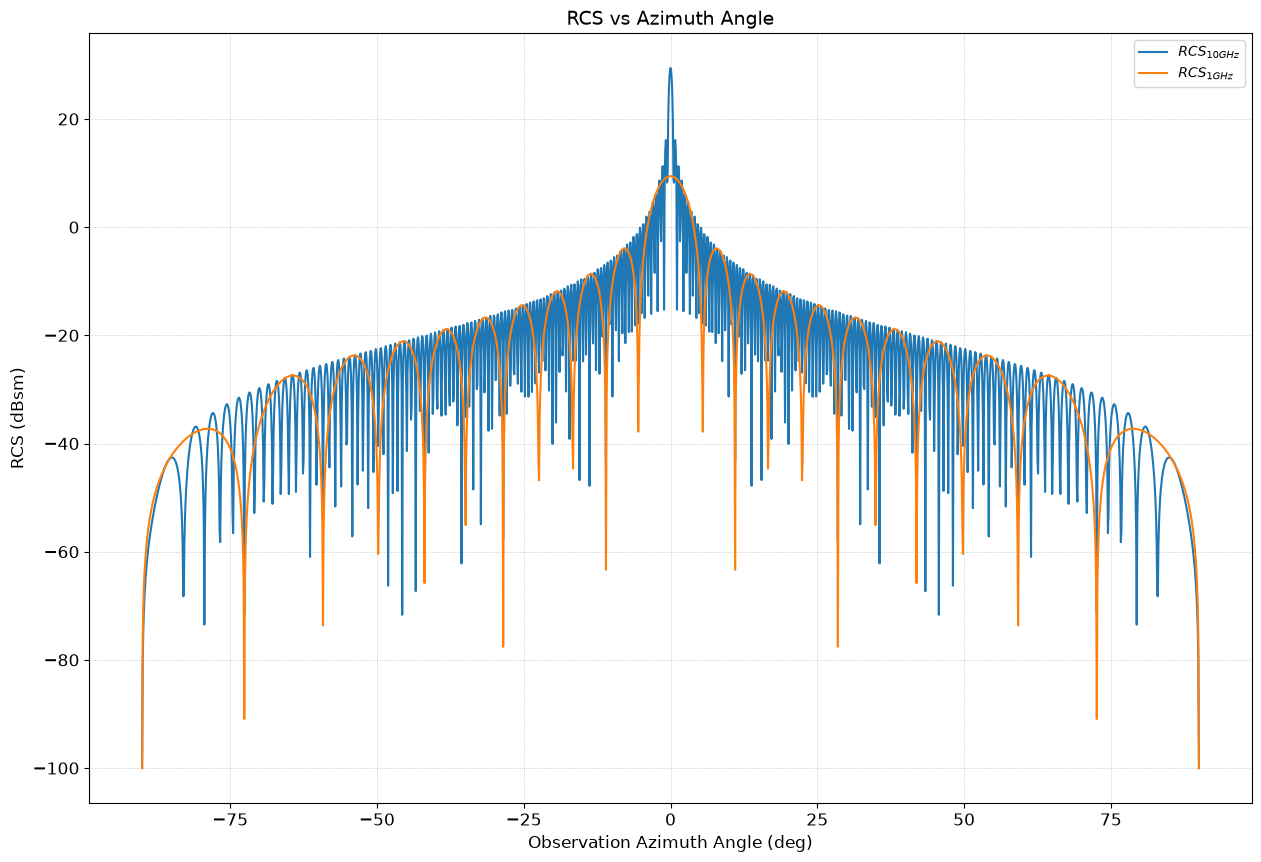

In [5]:
from matplotlib import pyplot as plt
from numpy import log10

# Set the figure size
plt.rcParams["figure.figsize"] = (15, 10)

# Display the results
plt.plot(observation_theta,rcs2dB, '', label='$RCS_{10 GHz}$')
plt.plot(observation_theta, rcs1dB, '', label='$RCS_{1 GHz}$')

# Set the plot title and labels
plt.title('RCS vs Azimuth Angle', size=14)
plt.ylabel('RCS (dBsm)', size=12)
plt.xlabel('Observation Azimuth Angle (deg)', size=12)
#plt.ylim(min(10.0 * log10(rcs + 1e-4)) - 3, max(10.0 * log10(rcs + 1e-4)) + 3)

# Set the tick label size
plt.tick_params(labelsize=12)

# Turn on the grid
plt.grid(linestyle=':', linewidth=0.5)

# Set the legend
plt.legend(loc='upper right', prop={'size': 10})

### Zoomed plot of the sector around $0^{\circ}$ azimuth

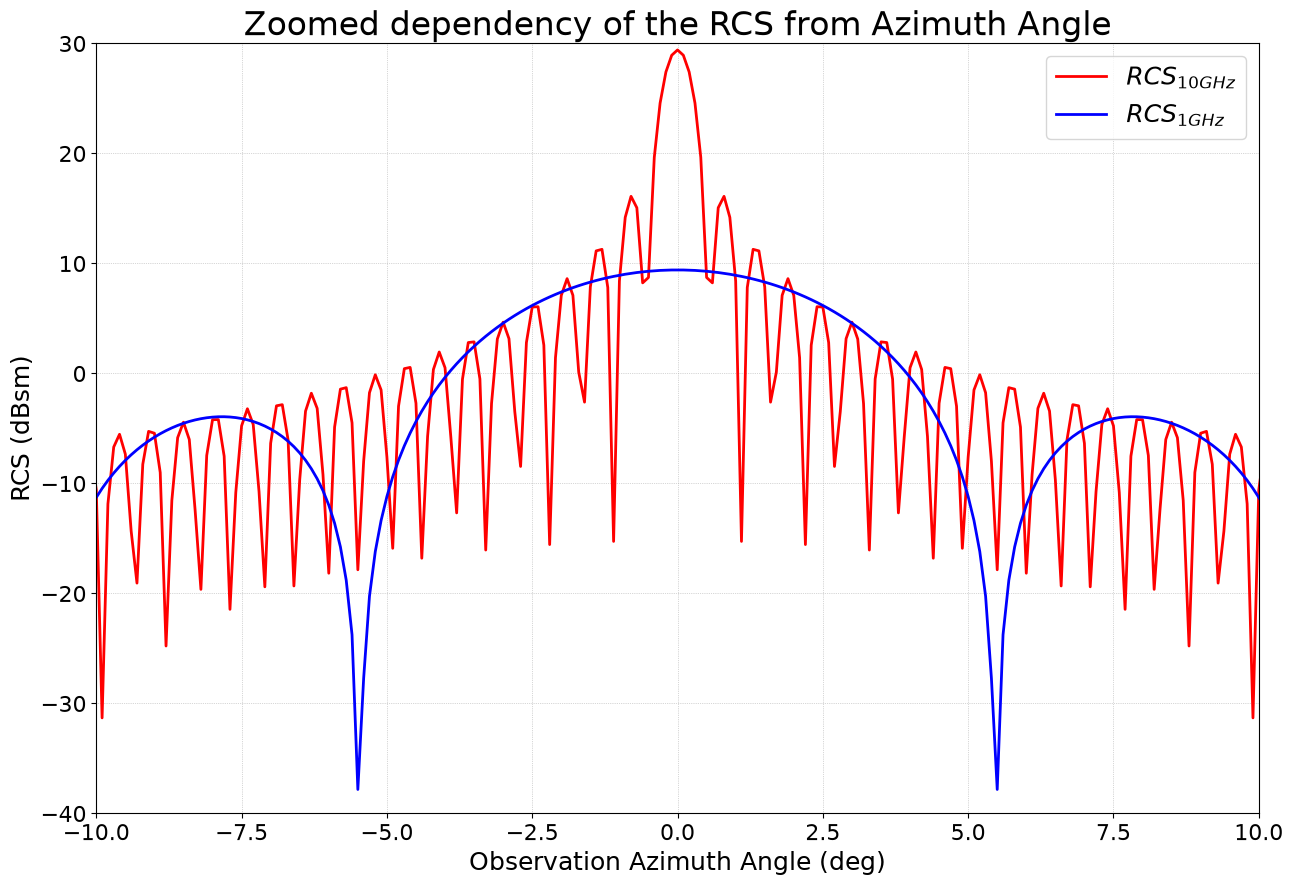

In [10]:
from matplotlib import pyplot as plt
from numpy import log10

# Set the figure size
plt.rcParams["figure.figsize"] = (15, 10)

# Display the results
plt.plot(observation_theta,rcs2dB, '', label='$RCS_{10 GHz}$', color='red', linewidth=2)
plt.plot(observation_theta, rcs1dB, '', label='$RCS_{1 GHz}$', color='blue', linewidth=2)

# Set the plot title and labels
plt.title('Zoomed dependency of the RCS from Azimuth Angle', size=24)
plt.ylabel('RCS (dBsm)', size=18)
plt.xlabel('Observation Azimuth Angle (deg)', size=18)
plt.xlim(-10.0, +10.0)
plt.ylim(-40.0, 30.0)

# Set the tick label size
plt.tick_params(labelsize=16)

# Turn on the grid
plt.grid(linestyle=':', linewidth=0.5)

# Set the legend
plt.legend(loc='upper right', prop={'size': 18},fontsize=18)
plt.show()